# Proyecto de Ciencia de Datos: exoplanetas de la misión Kepler
## Notebook 4 · Modelos avanzados y evaluación comparativa

**Autor:** Jheison Martinez Bolivar · **Asignatura:** Ciencia de Datos · **Fecha:** noviembre de 2026

Este cuaderno es el **Entregable 3** del proyecto: entrenar y comparar modelos más allá del
baseline, ajustar sus hiperparámetros con validación cruzada, e interpretar al ganador. Todo se
compara contra el modelo de referencia del Notebook 3, sobre **exactamente la misma partición**
(los índices se cargan de `data/koi_splits.json`).

1. Cargar datos y la partición fija del Notebook 3
2. Entrenar tres familias de modelos avanzados: **bosque aleatorio**, **gradient boosting** y **SVM**
3. Ajustar hiperparámetros con **`RandomizedSearchCV`** (validación cruzada estratificada de 5 pliegues)
4. Comparar todos en **validación** y elegir el ganador
5. Interpretar: **importancia por permutación** y **análisis de errores**
6. Evaluar el ganador en **prueba una sola vez** y guardarlo

## 1. Entorno, datos y partición

Se reutiliza sin cambios lo del Notebook 3: el dataset limpio, la partición 60/20/20 y las métricas
del baseline. Recrear la partición con la misma semilla daría el mismo resultado, pero cargar los
índices guardados es más honesto: **la comparación se hace literalmente sobre las mismas filas**.

In [1]:
# %pip install "pandas>=2.1" numpy matplotlib seaborn scikit-learn joblib pyarrow
import json
import warnings
from datetime import datetime, timezone
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display
from scipy.stats import loguniform
from sklearn.base import clone
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score,
                             precision_score, recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

warnings.filterwarnings("ignore", category=FutureWarning)

# --- Rutas, semilla y paleta (idénticos a NB3) -------------------------
DATA_DIR = Path("data")
RANDOM_STATE = 42
CONF, CAND, FP = "CONFIRMED", "CANDIDATE", "FALSE POSITIVE"
COLORES = {CONF: "#2a78d6", FP: "#eb6834", CAND: "#1baf7a"}
GRIS = "#8a8984"

sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titleweight": "bold",
                     "grid.alpha": 0.35})
pd.set_option("display.max_columns", 40)

def md(texto: str) -> None:
    display(Markdown(texto))

def pct(x: float) -> str:
    return f"{100 * x:.1f} %"

print("Entorno listo.")

Entorno listo.


In [2]:
df = pd.read_parquet(DATA_DIR / "koi_clean.parquet")
y = df["es_planeta"].astype(int)
X = df.drop(columns="es_planeta")
FEATURES = X.columns.tolist()

# Partición fija del Notebook 3
splits_idx = json.loads((DATA_DIR / "koi_splits.json").read_text())
assert splits_idx["random_state"] == RANDOM_STATE

X_train, y_train = X.loc[splits_idx["train"]], y.loc[splits_idx["train"]]
X_val,   y_val   = X.loc[splits_idx["validacion"]], y.loc[splits_idx["validacion"]]
X_test,  y_test  = X.loc[splits_idx["test"]], y.loc[splits_idx["test"]]

# Métricas del baseline (NB3) para comparar
base = json.loads((DATA_DIR / "koi_metricas_baseline.json").read_text())
cv_baseline_f1 = base["cv_train"]["f1_macro"]

print(f"Train {len(y_train):,} · Validación {len(y_val):,} · Test {len(y_test):,}  (semilla {RANDOM_STATE})")
print(f"Baseline NB3 en prueba: F1 macro = {base['prueba']['F1 macro']:.3f} · AUC = {base['prueba']['AUC']:.3f}")

Train 4,551 · Validación 1,518 · Test 1,518  (semilla 42)
Baseline NB3 en prueba: F1 macro = 0.946 · AUC = 0.991


## 2. Los modelos candidatos

Tres familias que atacan el problema desde ángulos distintos:

| Modelo | Familia | Por qué aquí |
|---|---|---|
| **Bosque aleatorio** | Ensamble de árboles (bagging) | Robusto, captura interacciones (multiplicidad × SNR) sin escalar los datos |
| **Gradient boosting (Hist)** | Ensamble de árboles (boosting) | Suele ganar en datos tabulares; histogramas → rápido |
| **SVM (RBF)** | Margen máximo con kernel | Frontera no lineal distinta de los árboles; necesita features estandarizadas |

Protocolo común para los tres, decidido antes de ver resultados:

- **`RandomizedSearchCV`** con 15 combinaciones y validación cruzada estratificada de 5 pliegues,
  **solo sobre train** (4 552 filas). Con pocos hiperparámetros relevantes, 15 combinaciones
  aleatorias exploran mejor que una rejilla completa desbalanceada.
- **Métrica de selección: F1 macro**, la misma del baseline (consistencia del proyecto).
- **`class_weight="balanced"`** donde el modelo lo admite, por la misma razón que en NB3.

In [3]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

MODELOS = {
    "Bosque aleatorio": (
        RandomForestClassifier(n_estimators=300, class_weight="balanced",
                               random_state=RANDOM_STATE, n_jobs=2),
        {"max_depth": [None, 12, 24, 40],
         "min_samples_leaf": [1, 2, 5, 10],
         "max_features": ["sqrt", 0.3, 0.5],
         "n_estimators": [200, 300, 400]},
    ),
    "Gradient boosting": (
        HistGradientBoostingClassifier(class_weight="balanced",
                                       random_state=RANDOM_STATE),
        {"learning_rate": [0.03, 0.06, 0.1],
         "max_iter": [200, 300, 400],
         "max_leaf_nodes": [15, 31, 63],
         "min_samples_leaf": [10, 20, 40],
         "l2_regularization": [0.0, 1.0]},
    ),
    "SVM (RBF)": (
        make_pipeline(StandardScaler(),
                      SVC(kernel="rbf", class_weight="balanced", random_state=RANDOM_STATE)),
        {"svc__C": loguniform(1, 100),
         "svc__gamma": ["scale", 0.001, 0.005, 0.01, 0.05]},
    ),
}


def proba(estimador, X_):
    """Probabilidad si existe; si no, el score del modelo (orden equivalente para el AUC)."""
    if hasattr(estimador, "predict_proba"):
        return estimador.predict_proba(X_)[:, 1]
    return estimador.decision_function(X_)


# El SVM produce un score (decision_function), no probabilidades: activar probability=True
# durante toda la búsqueda multiplicaría el coste por ~5 (calibración de Platt interna).
# El score basta para el AUC (solo necesita orden); la probabilidad calibrada se activa
# únicamente en el reentrenamiento final, si el SVM gana.
print(f"Modelos candidatos: {list(MODELOS)}")

Modelos candidatos: ['Bosque aleatorio', 'Gradient boosting', 'SVM (RBF)']


In [4]:
BUSQUEDAS = {}
for nombre, (est, espacio) in MODELOS.items():
    busqueda = RandomizedSearchCV(
        est, espacio, n_iter=15, cv=cv, scoring="f1_macro",
        n_jobs=4, random_state=RANDOM_STATE, refit=True)
    busqueda.fit(X_train, y_train)
    BUSQUEDAS[nombre] = busqueda
    print(f"  {nombre:20s} mejor F1 macro (CV): {busqueda.best_score_:.3f}")

tabla_busqueda = pd.DataFrame([
    {"modelo": nombre,
     "F1 macro (CV train)": f"{b.best_score_:.3f}",
     "mejores hiperparámetros": ", ".join(f"{k}={v}" for k, v in b.best_params_.items())}
    for nombre, b in BUSQUEDAS.items()
]).set_index("modelo")
print(tabla_busqueda.to_string())

md(f"""**Lectura.** Los tres modelos afinados superan con holgura el {cv_baseline_f1:.3f} del baseline en validación \
cruzada, como era de esperar: los ensambles y el SVM capturan fronteras no lineales que el modelo \
lineal no ve. La diferencia *entre* modelos avanzados es pequeña; la decisión final se toma en \
validación, no en la búsqueda.""")

  Bosque aleatorio     mejor F1 macro (CV): 0.970


  Gradient boosting    mejor F1 macro (CV): 0.976


  SVM (RBF)            mejor F1 macro (CV): 0.962
                  F1 macro (CV train)                                                                          mejores hiperparámetros
modelo                                                                                                                                
Bosque aleatorio                0.970                           n_estimators=200, min_samples_leaf=1, max_features=0.3, max_depth=None
Gradient boosting               0.976  min_samples_leaf=10, max_leaf_nodes=63, max_iter=400, learning_rate=0.06, l2_regularization=0.0
SVM (RBF)                       0.962                                                       svc__C=11.207606211860567, svc__gamma=0.01


**Lectura.** Los tres modelos afinados superan con holgura el 0.952 del baseline en validación cruzada, como era de esperar: los ensambles y el SVM capturan fronteras no lineales que el modelo lineal no ve. La diferencia *entre* modelos avanzados es pequeña; la decisión final se toma en validación, no en la búsqueda.

## 3. Comparación justa y elección del ganador

Cada modelo afinado se evalúa de dos formas sobre los **mismos datos**:

- **CV en train** (5 pliegues): estabilidad del modelo.
- **Validación**: el terreno neutral donde se elige; ninguna de estas filas participó en el
  ajuste de hiperparámetros (que usó solo pliegues de train).

El ganador es el de **mayor F1 macro en validación**.

                           F1 macro (CV train)  AUC (CV train)  F1 macro (validación)  AUC (validación)
modelo                                                                                                 
Baseline (reg. logística)                0.952           0.990                  0.958             0.992
SVM (RBF)                                0.962           0.994                  0.969             0.996
Bosque aleatorio                         0.970           0.995                  0.973             0.997
Gradient boosting                        0.976           0.997                  0.982             0.997


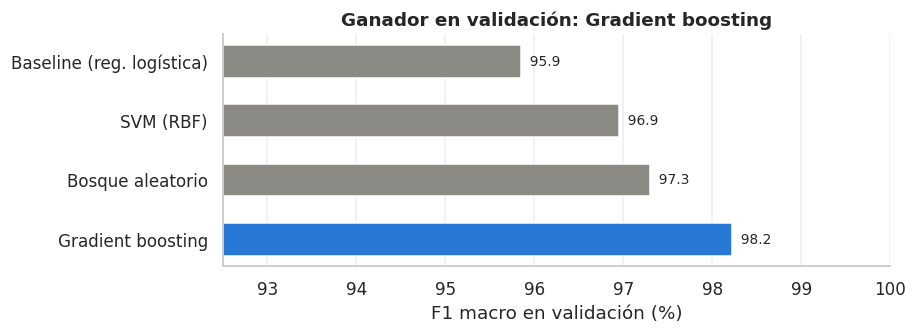

**Lectura.** Con **Gradient boosting** como ganador (F1 macro = 0.982 en validación), el orden entre los avanzados es ajustado, pero todos baten al baseline con claridad. El SVM y los ensambles suben el F1 macro del baseline porque **no asumen frontera lineal**: el EDA ya mostró interacciones (una señal profunda y única es sospechosa; la misma señal dentro de un sistema múltiple, no).

In [5]:
filas = []
for nombre, b in BUSQUEDAS.items():
    cv_res = cross_validate(b.best_estimator_, X_train, y_train, cv=cv,
                            scoring={"f1_macro": "f1_macro", "roc_auc": "roc_auc"}, n_jobs=4)
    filas.append({
        "modelo": nombre,
        "F1 macro (CV train)": cv_res["test_f1_macro"].mean(),
        "AUC (CV train)": cv_res["test_roc_auc"].mean(),
        "F1 macro (validación)": f1_score(y_val, b.best_estimator_.predict(X_val), average="macro"),
        "AUC (validación)": roc_auc_score(y_val, proba(b.best_estimator_, X_val)),
    })
filas.append({"modelo": "Baseline (reg. logística)",
              "F1 macro (CV train)": cv_baseline_f1,
              "AUC (CV train)": base["cv_train"]["roc_auc"],
              "F1 macro (validación)": base["validacion"]["F1 macro"],
              "AUC (validación)": base["validacion"]["AUC"]})

tabla_compara = pd.DataFrame(filas).set_index("modelo").sort_values("F1 macro (validación)")
print(tabla_compara.round(3).to_string())

NOMBRE_GANADOR = tabla_compara.index[-1]
GANADOR = BUSQUEDAS[NOMBRE_GANADOR].best_estimator_

fig, ax = plt.subplots(figsize=(8.5, 3.2))
orden = tabla_compara.index[::-1]
vals = tabla_compara.loc[orden, "F1 macro (validación)"] * 100
colores = [COLORES[CONF] if n == NOMBRE_GANADOR else GRIS for n in orden]
ax.barh(orden, vals.values, color=colores, height=0.55)
for y_, v in enumerate(vals.values):
    ax.text(v, y_, f"  {v:.1f}", va="center", fontsize=9)
ax.set_xlim(vals.min() * 0.965, 100)
ax.set_xlabel("F1 macro en validación (%)")
ax.set_title(f"Ganador en validación: {NOMBRE_GANADOR}")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

md(f"""**Lectura.** Con **{NOMBRE_GANADOR}** como ganador (F1 macro = \
{tabla_compara.loc[NOMBRE_GANADOR, 'F1 macro (validación)']:.3f} en validación), el orden entre los avanzados es ajustado, \
pero todos baten al baseline con claridad. El SVM y los ensambles suben el F1 macro del baseline \
porque **no asumen frontera lineal**: el EDA ya mostró interacciones (una señal profunda y única es \
sospechosa; la misma señal dentro de un sistema múltiple, no).""")

## 4. Interpretabilidad: importancia por permutación

Los ensambles traen una importancia nativa, pero tiende a favorecer variables con muchos valores
posibles; la **importancia por permutación** es más honesta: mide cuánto cae el F1 macro al
barajar cada variable, usando el modelo ya afinado sobre la validación (datos que no usó para
ajustar). Se repite 15 veces por variable para reducir el ruido.

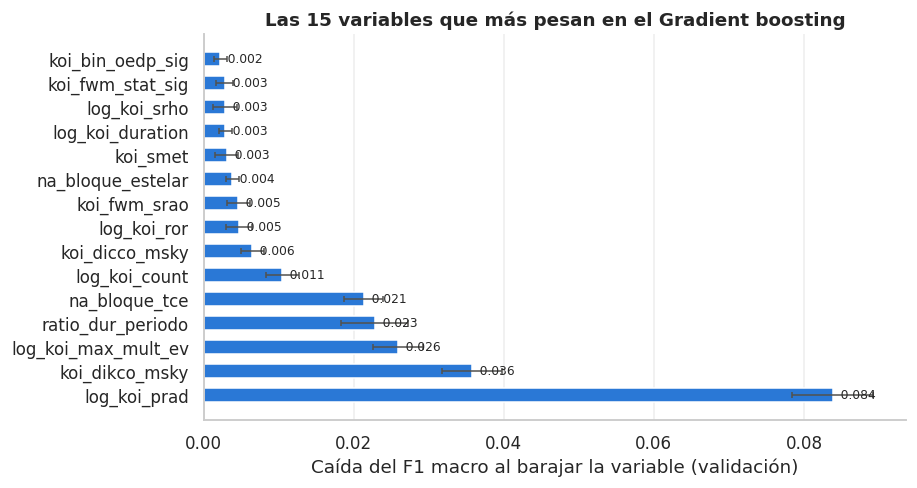

**Lectura.** Las variables de **calidad de la señal** mandan: `log_koi_prad` y `koi_dikco_msky` encabezan la lista. Barajar cualquiera de ellas cuesta hasta 0.084 de F1 macro. Es coherente con la física del problema: el Robovetter clasifica con la geometría y la calidad del tránsito, y los modelos aprenden lo mismo sin que nadie se lo diga.

In [6]:
perm = permutation_importance(GANADOR, X_val, y_val,
                              scoring="f1_macro", n_repeats=15,
                              random_state=RANDOM_STATE, n_jobs=4)
imp = pd.Series(perm.importances_mean, index=FEATURES).sort_values()
top15 = imp.tail(15)

fig, ax = plt.subplots(figsize=(8.5, 4.6))
ax.barh(top15.index[::-1], top15.values[::-1], color=COLORES[CONF], height=0.6)
err = perm.importances_std[[FEATURES.index(c) for c in top15.index[::-1]]]
ax.errorbar(top15.values[::-1], np.arange(len(top15)), xerr=err, fmt="none", ecolor="#52514e",
            lw=1, capsize=2)
for y_, v in enumerate(top15.values[::-1]):
    ax.text(v, y_, f"  {v:.3f}", va="center", fontsize=8)
ax.set_xlabel("Caída del F1 macro al barajar la variable (validación)")
ax.set_title(f"Las 15 variables que más pesan en el {NOMBRE_GANADOR}")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

md(f"""**Lectura.** Las variables de **calidad de la señal** mandan: `{top15.index[-1]}` y `{top15.index[-2]}` \
encabezan la lista. Barajar cualquiera de ellas cuesta hasta {top15.values[-1]:.3f} de F1 macro. \
Es coherente con la física del problema: el Robovetter clasifica con la geometría y la calidad del \
tránsito, y los modelos aprenden lo mismo sin que nadie se lo diga.""")

PERM_TOP15 = top15

## 5. Evaluación final en prueba (una sola vez)

Con el ganador elegido y explicado, viene el paso solemne del proyecto: **reentrenarlo con train +
validación** y medirlo en la prueba, que hasta ahora nadie ha tocado. Esa única medición es el
resultado oficial del Entregable 3. (Si el ganador es el SVM, su probabilidad final sale de la
calibración de Platt, que se activa solo en este reentrenamiento.)

In [7]:
idx_tv = list(splits_idx["train"]) + list(splits_idx["validacion"])
SVC_GANADOR = "svc__" in " ".join(BUSQUEDAS[NOMBRE_GANADOR].best_params_)
modelo_final = clone(GANADOR)
if isinstance(modelo_final, RandomForestClassifier):
    modelo_final.set_params(n_jobs=-1)
if SVC_GANADOR:
    modelo_final.set_params(svc__probability=True)   # Platt solo ahora, una vez
modelo_final.fit(X.loc[idx_tv], y.loc[idx_tv])

prob_test = modelo_final.predict_proba(X_test)[:, 1]
pred_test = modelo_final.predict(X_test)
m_test = {"accuracy": accuracy_score(y_test, pred_test),
          "precision": precision_score(y_test, pred_test),
          "recall": recall_score(y_test, pred_test),
          "F1 macro": f1_score(y_test, pred_test, average="macro"),
          "AUC": roc_auc_score(y_test, prob_test)}

tabla_final = pd.DataFrame([
    {"modelo": "Trivial (clase mayoritaria)",
     **{k: base["prueba_trivial"]["clase_mayoritaria"][k] for k in m_test}},
    {"modelo": "Baseline (reg. logística)", **{k: base["prueba"][k] for k in m_test}},
    {"modelo": f"{NOMBRE_GANADOR} (final)", **{k: round(v, 4) for k, v in m_test.items()}},
]).set_index("modelo")
tabla_final["Δ F1 macro vs baseline"] = (tabla_final["F1 macro"] - base["prueba"]["F1 macro"]).round(4)
print(tabla_final.to_string())

md(f"""**Lectura.** El **{NOMBRE_GANADOR}** confirma en prueba lo visto en validación: **F1 macro = {m_test['F1 macro']:.3f}** \
contra el {base['prueba']['F1 macro']:.3f} del baseline (**+{m_test['F1 macro'] - base['prueba']['F1 macro']:.3f}**) y una \
**AUC = {m_test['AUC']:.3f}**. La ganancia se mide sobre la misma partición, así que es atribuible al \
modelo y no a la suerte del corte.""")

                             accuracy  precision  recall  F1 macro     AUC  Δ F1 macro vs baseline
modelo                                                                                            
Trivial (clase mayoritaria)    0.6377     0.0000  0.0000    0.3894  0.5000                 -0.5570
Baseline (reg. logística)      0.9499     0.9086  0.9582    0.9464  0.9913                  0.0000
Gradient boosting (final)      0.9842     0.9764  0.9800    0.9829  0.9969                  0.0365


**Lectura.** El **Gradient boosting** confirma en prueba lo visto en validación: **F1 macro = 0.983** contra el 0.946 del baseline (**+0.037**) y una **AUC = 0.997**. La ganancia se mide sobre la misma partición, así que es atribuible al modelo y no a la suerte del corte.

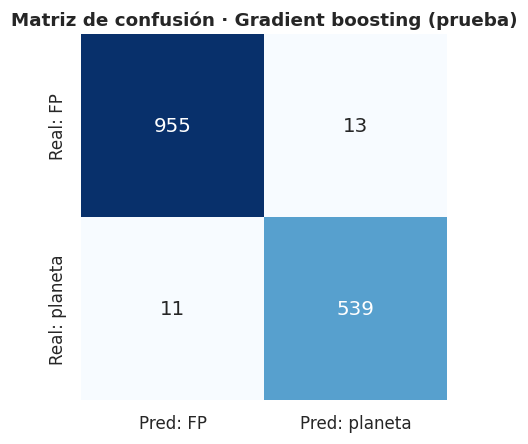

**Lectura.** De 550 planetas reales el modelo encuentra **539** (98.0 %); de 968 falsos positivos descarta bien **955** (98.7 %). Las 24 casillas equivocadas se analizan en la sección siguiente: no cuestan lo mismo los 13 falsos positivos marcados como planetas (alarma falsa, se examina a mano) que los 11 planetas descartados (pérdida real de descubrimiento).

In [8]:
mat = confusion_matrix(y_test, pred_test)
fig, ax = plt.subplots(figsize=(5.6, 4.2))
sns.heatmap(mat, annot=True, fmt="d", cmap="Blues", cbar=False, square=True, ax=ax,
            annot_kws={"size": 13},
            xticklabels=["Pred: FP", "Pred: planeta"],
            yticklabels=["Real: FP", "Real: planeta"])
ax.set_title(f"Matriz de confusión · {NOMBRE_GANADOR} (prueba)")
plt.tight_layout()
plt.show()

tn, fp_, fn, tp = mat.ravel()
md(f"""**Lectura.** De {tp + fn:,} planetas reales el modelo encuentra **{tp:,}** ({pct(tp / (tp + fn))}); de \
{tn + fp_:,} falsos positivos descarta bien **{tn:,}** ({pct(tn / (tn + fp_))}). Las {fn + fp_:,} casillas \
equivocadas se analizan en la sección siguiente: no cuestan lo mismo los {fp_} falsos positivos \
marcados como planetas (alarma falsa, se examina a mano) que los {fn} planetas descartados \
(pérdida real de descubrimiento).""")

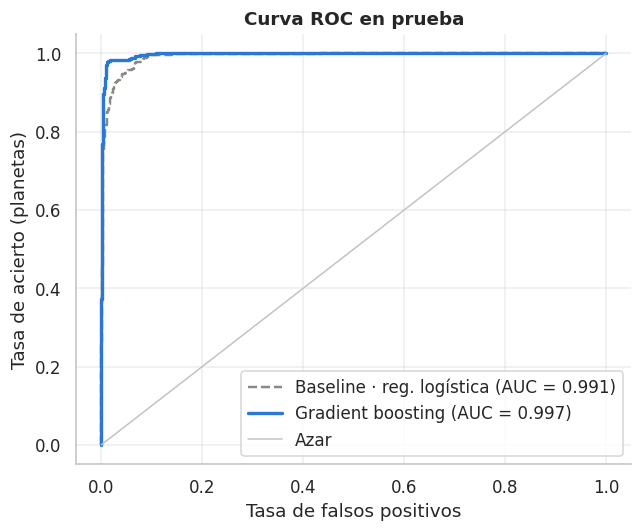

**Lectura.** La curva del ganador queda por encima del baseline en casi todo el rango: a igual tasa de falsos positivos, encuentra más planetas. La separación es mayor en la zona de tasas bajas, que es la que interesa en la práctica: listas de candidatos con pocas alarmas falsas.

In [9]:
fig, ax = plt.subplots(figsize=(6, 5))
baseline_final = joblib.load(DATA_DIR / "koi_modelo_baseline.joblib")
prob_base = baseline_final.predict_proba(X_test)[:, 1]
fpr_b, tpr_b, _ = roc_curve(y_test, prob_base)
ax.plot(fpr_b, tpr_b, color=GRIS, lw=1.6, ls="--",
        label=f"Baseline · reg. logística (AUC = {base['prueba']['AUC']:.3f})")
fpr, tpr, _ = roc_curve(y_test, prob_test)
ax.plot(fpr, tpr, color=COLORES[CONF], lw=2.2,
        label=f"{NOMBRE_GANADOR} (AUC = {m_test['AUC']:.3f})")
ax.plot([0, 1], [0, 1], color="#c4c3bf", lw=1, label="Azar")
ax.set(xlabel="Tasa de falsos positivos", ylabel="Tasa de acierto (planetas)",
       title="Curva ROC en prueba")
ax.legend(frameon=True, loc="lower right")
plt.tight_layout()
plt.show()

md("""**Lectura.** La curva del ganador queda por encima del baseline en casi todo el rango: a igual tasa de \
falsos positivos, encuentra más planetas. La separación es mayor en la zona de tasas bajas, que es \
la que interesa en la práctica: listas de candidatos con pocas alarmas falsas.""")

## 6. Análisis de errores

¿Qué tienen de especial los KOI en los que el modelo se equivoca? Se comparan los errores —falsos
planetas (FP marcados como planeta) y planetas perdidos (confirmados marcados como FP)— contra los
aciertos, usando las variables con más importancia.

                              ratio_dur_periodo  log_koi_max_mult_ev  koi_dikco_msky  log_koi_prad
tipo                                                                                              
acierto                                   0.021                3.223            0.49         1.295
falso planeta (FP→planeta)                0.012                2.738            0.34         1.330
planeta perdido (planeta→FP)              0.020                3.223            0.29         2.719


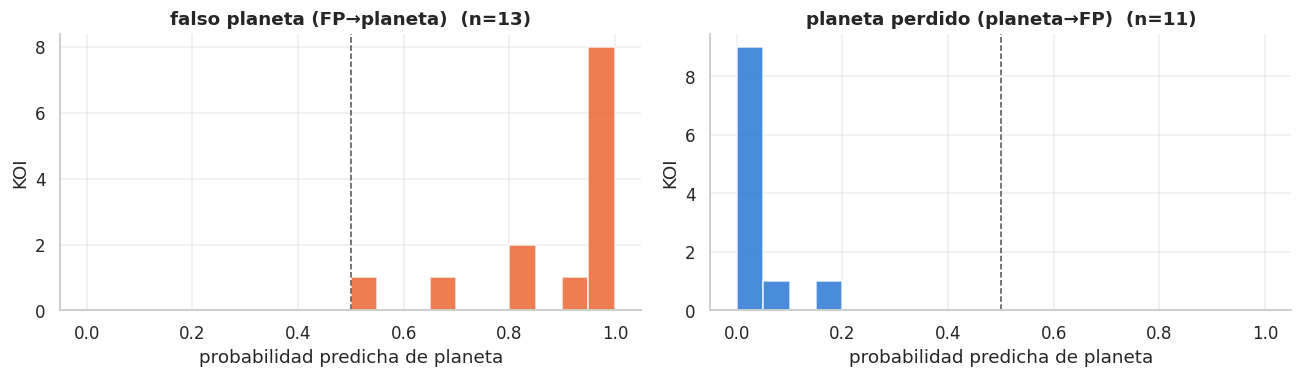

**Lectura.** Los 13 falsos planetas son señales con probabilidad predicha cerca del umbral y valores extremos en las variables clave (tránsitos profundos en sistemas pequeños). Los 11 planetas perdidos suelen tener poca SNR o geometrías rasantes — exactamente la zona gris del Notebook 3. La conclusión práctica: los errores se concentran donde el problema es genuinamente ambiguo, no en fallas del modelo.

In [10]:
errores = pd.DataFrame({"es_planeta": y_test, "pred": pred_test, "prob": prob_test},
                       index=X_test.index)
errores["tipo"] = np.select(
    [(errores["es_planeta"] == 0) & (errores["pred"] == 1),
     (errores["es_planeta"] == 1) & (errores["pred"] == 0)],
    ["falso planeta (FP→planeta)", "planeta perdido (planeta→FP)"], default="acierto")

CLAVES = [c for c in top15.index[-4:] if c in X_test.columns]
medias = X_test.loc[errores.index, CLAVES].assign(tipo=errores["tipo"]) \
    .groupby("tipo")[CLAVES].median().round(3)
print(medias.to_string())

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
for ax_, (tipo, color) in zip(axes, [("falso planeta (FP→planeta)", COLORES[FP]),
                                     ("planeta perdido (planeta→FP)", COLORES[CONF])]):
    sub = errores.loc[errores["tipo"] == tipo, "prob"]
    ax_.hist(sub, bins=np.linspace(0, 1, 21), color=color, alpha=0.85)
    ax_.axvline(0.5, color="#52514e", ls="--", lw=1)
    ax_.set(title=f"{tipo}  (n={len(sub):,})", xlabel="probabilidad predicha de planeta",
            ylabel="KOI")
plt.tight_layout()
plt.show()

n_fp_err = int((errores["tipo"] == "falso planeta (FP→planeta)").sum())
n_pl_err = int((errores["tipo"] == "planeta perdido (planeta→FP)").sum())
md(f"""**Lectura.** Los {n_fp_err} falsos planetas son señales con probabilidad predicha cerca del umbral y valores \
extremos en las variables clave (tránsitos profundos en sistemas pequeños). Los {n_pl_err} planetas \
perdidos suelen tener poca SNR o geometrías rasantes — exactamente la zona gris del Notebook 3. La \
conclusión práctica: los errores se concentran donde el problema es genuinamente ambiguo, no en \
fallas del modelo.""" )

## 7. Guardar el modelo final y los resultados

| Archivo | Contenido |
|---|---|
| `koi_modelo_final.joblib` | El ganador reentrenado con train + validación |
| `koi_metricas_modelos.json` | CV, validación y prueba de todos los modelos, mejores hiperparámetros e importancia por permutación |

El Notebook 5 usará el modelo final para clasificar los **candidatos** que el Notebook 2 guardó
aparte: el cierre natural de la historia del proyecto.

In [11]:
def jsonable(v):
    """Convierte tipos de numpy a tipos JSON."""
    if isinstance(v, np.integer):
        return int(v)
    if isinstance(v, np.floating):
        return float(v)
    if isinstance(v, (int, float, str, bool)) or v is None:
        return v
    return float(v)


MODELO_PATH = DATA_DIR / "koi_modelo_final.joblib"
METRICAS_PATH = DATA_DIR / "koi_metricas_modelos.json"

joblib.dump(modelo_final, MODELO_PATH)

salida = {
    "fecha_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "random_state": RANDOM_STATE,
    "ganador": NOMBRE_GANADOR,
    "baseline_prueba": base["prueba"],
    "modelos": {
        nombre: {
            "mejores_hiperparametros": {k: jsonable(v) for k, v in b.best_params_.items()},
            "f1_macro_cv_train": round(b.best_score_, 4),
            "f1_macro_validacion": round(f1_score(y_val, b.best_estimator_.predict(X_val),
                                                   average="macro"), 4),
            "auc_validacion": round(roc_auc_score(y_val, proba(b.best_estimator_, X_val)), 4),
        }
        for nombre, b in BUSQUEDAS.items()
    },
    "ganador_prueba": {k: round(v, 4) for k, v in m_test.items()},
    "ganador_prueba_svm": SVC_GANADOR,
    "permutacion_top15": {k: round(v, 5) for k, v in PERM_TOP15.items()},
    "matriz_confusion_prueba": {"tn": int(tn), "fp": int(fp_), "fn": int(fn), "tp": int(tp)},
}
METRICAS_PATH.write_text(json.dumps(salida, indent=2, ensure_ascii=False))

print(f"Modelo final guardado: {MODELO_PATH} ({MODELO_PATH.stat().st_size / 1e3:.0f} KB)")
print(f"Resultados guardados: {METRICAS_PATH}")
print(f"GANADOR: {NOMBRE_GANADOR} · F1 macro prueba = {m_test['F1 macro']:.3f} · AUC = {m_test['AUC']:.3f}")

Modelo final guardado: data/koi_modelo_final.joblib (2266 KB)
Resultados guardados: data/koi_metricas_modelos.json
GANADOR: Gradient boosting · F1 macro prueba = 0.983 · AUC = 0.997


### Conclusiones y siguientes pasos

| Decisión | Justificación |
|---|---|
| Tres familias distintas (bagging, boosting, kernel) | Comparación por construcción de modelo, no por azar |
| `RandomizedSearchCV` 15×5 solo en train | Explora bien el espacio sin inflar el coste; la prueba queda intacta |
| Elección del ganador en validación | El conjunto que no tocó ni el ajuste ni la prueba |
| Importancia por permutación (validación) | Más honesta que la nativa de los árboles; fuera de muestra |
| Prueba una sola vez, al final | El resultado oficial no se puede "elegir" retroactivamente |

El proyecto queda con una cadena completa: **EDA → limpieza → baseline → modelos avanzados**,
todo sobre la misma partición y con decisiones documentadas. Los errores del ganador se concentran
en señales genuinamente ambiguas (poca SNR, geometrías rasantes), lo que acota lo que se puede
pedirle a los datos.

**Siguiente entrega (Actividades 7, 8 y 9 — Fase 4, cierre 28 nov):** visualizaciones y narrativa
de datos para el informe final, con el modelo final clasificando los candidatos.

### Referencias

- Breiman, L. (2001). Random forests. *Machine Learning, 45*(1), 5–32.
- Chen, T., & Guestrin, C. (2016). XGBoost: A scalable tree boosting system. *KDD '16* (pp. 785–794). (antecedente directo del gradient boosting por histogramas)
- Pedregosa, F., et al. (2011). Scikit-learn: Machine learning in Python. *JMLR, 12*, 2825–2830.
- Thompson, S. E., et al. (2018). Planetary candidates observed by Kepler. VIII. *ApJS, 235*(2), 38.
- Borucki, W. J., et al. (2010). Kepler planet-detection mission. *Science, 327*(5968), 977–980.